# 05 – Robustness Across Reliability Thresholds
Show the occurrence-rate drop is stable.

In [3]:
# 1. Imports and configuration

import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    balanced_accuracy_score, roc_auc_score,
    average_precision_score, brier_score_loss
)

RANDOM_STATE = 42
N_SPLITS = 5

# Thresholds to evaluate. A denser sweep can be used later if justified.
THRESHOLDS = np.round(np.arange(0.30, 0.701, 0.05), 2)

# Kepler KOI dataset location used in the earlier notebooks.
DATA_PATH = (
    "/kaggle/input/datasets/sairakeshnagaram/"
    "koi-dataset/cumulative_2026.10.20_19.25.07.csv"
)

FEATURES = [
    "koi_period", "koi_time0bk", "koi_impact", "koi_duration",
    "koi_depth", "koi_prad", "koi_teq", "koi_insol",
    "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag"
]

print("Thresholds:", THRESHOLDS)
print("Number of folds:", N_SPLITS)
print("Dataset path:", DATA_PATH)

Thresholds: [0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7 ]
Number of folds: 5
Dataset path: /kaggle/input/datasets/sairakeshnagaram/koi-dataset/cumulative_2026.10.20_19.25.07.csv


In [4]:
# 2. Load and filter the KOI catalog

if not os.path.exists(DATA_PATH):
    candidates = glob.glob("/kaggle/input/**/*.csv", recursive=True)
    print("CSV files available under /kaggle/input:")
    for path in candidates[:100]:
        print(path)
    raise FileNotFoundError(
        "The expected KOI CSV was not found. Update DATA_PATH using "
        "one of the CSV paths printed above."
    )


# Automatically locate the actual Kepler CSV header

header_row = None

with open(DATA_PATH, "r", encoding="utf-8-sig") as f:
    for i, line in enumerate(f):
        if "kepid" in line and "koi_disposition" in line:
            header_row = i
            break

if header_row is None:
    raise ValueError(
        "Could not locate the Kepler CSV header. "
        "Check that DATA_PATH points to the correct dataset."
    )

print("Detected CSV header at line:", header_row + 1)

raw = pd.read_csv(
    DATA_PATH,
    skiprows=header_row,
    engine="python"
)

print("Raw dataset shape:", raw.shape)
print("Columns:", raw.columns.tolist())
display(raw.head())
print("Raw dataset shape:", raw.shape)

required_columns = [
    "kepid", "koi_disposition", "koi_prad", "koi_steff"
] + FEATURES
missing = [c for c in required_columns if c not in raw.columns]
if missing:
    raise ValueError(f"Required columns missing from dataset: {missing}")

catalog = raw[
    raw["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE", "CANDIDATE"])
].copy()

catalog = catalog[
    catalog["koi_prad"].between(1, 4, inclusive="both")
    & catalog["koi_steff"].between(4700, 6500, inclusive="both")
    & catalog["kepid"].notna()
].copy()

print("Filtered catalog rows:", len(catalog))
print("Unique host stars:", catalog["kepid"].nunique())
print("\nDisposition counts:")
display(catalog["koi_disposition"].value_counts())

# Candidates remain in the catalog description but are not labeled training examples.
resolved = catalog[
    catalog["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])
].copy()

resolved["label"] = (
    resolved["koi_disposition"] == "CONFIRMED"
).astype(int)

X = resolved[FEATURES].apply(pd.to_numeric, errors="coerce")
y = resolved["label"].astype(int)
groups = resolved["kepid"]

print("\nResolved training rows:", len(resolved))
print("Unique host stars in training:", groups.nunique())
print("Class counts (0=false positive, 1=confirmed):")
display(y.value_counts().sort_index())

Detected CSV header at line: 54
Raw dataset shape: (9564, 49)
Columns: ['kepid', 'kepoi_name', 'kepler_name', 'koi_disposition', 'koi_pdisposition', 'koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_period', 'koi_period_err1', 'koi_period_err2', 'koi_time0bk', 'koi_time0bk_err1', 'koi_time0bk_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_prad', 'koi_prad_err1', 'koi_prad_err2', 'koi_teq', 'koi_teq_err1', 'koi_teq_err2', 'koi_insol', 'koi_insol_err1', 'koi_insol_err2', 'koi_model_snr', 'koi_tce_plnt_num', 'koi_tce_delivname', 'koi_steff', 'koi_steff_err1', 'koi_steff_err2', 'koi_slogg', 'koi_slogg_err1', 'koi_slogg_err2', 'koi_srad', 'koi_srad_err1', 'koi_srad_err2', 'ra', 'dec', 'koi_kepmag']


,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,10811496,K00753.01,NaN,CANDIDATE,CANDIDATE,0.000,0,0,0,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


Raw dataset shape: (9564, 49)
Filtered catalog rows: 4249
Unique host stars: 3517

Disposition counts:


koi_disposition
CONFIRMED         1966
FALSE POSITIVE    1229
CANDIDATE         1054
Name: count, dtype: int64


Resolved training rows: 3195
Unique host stars in training: 2654
Class counts (0=false positive, 1=confirmed):


label
0    1229
1    1966
Name: count, dtype: int64

In [5]:
# 3. Cross-validation and out-of-fold probabilities

def make_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE,
            class_weight="balanced",
            n_jobs=-1
        ))
    ])

def generate_oof_predictions(splitter, X, y, groups=None, design_name="CV"):
    oof = np.full(len(X), np.nan, dtype=float)
    test_counts = np.zeros(len(X), dtype=int)
    fold_sizes = []

    split_iter = (
        splitter.split(X, y, groups)
        if groups is not None
        else splitter.split(X, y)
    )

    for fold, (train_idx, test_idx) in enumerate(split_iter, start=1):
        if len(np.unique(y.iloc[train_idx])) < 2:
            raise ValueError(f"{design_name}, fold {fold}: training data has only one class.")
        if len(np.unique(y.iloc[test_idx])) < 2:
            raise ValueError(
                f"{design_name}, fold {fold}: test data has only one class. "
                "Do not silently calculate threshold metrics for this fold."
            )

        if groups is not None:
            train_groups = set(groups.iloc[train_idx])
            test_groups = set(groups.iloc[test_idx])
            overlap = train_groups.intersection(test_groups)
            if overlap:
                raise RuntimeError(
                    f"Host-star leakage detected in {design_name}, fold {fold}."
                )

        model = make_model()
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        positive_col = list(model.named_steps["classifier"].classes_).index(1)
        probabilities = model.predict_proba(X.iloc[test_idx])[:, positive_col]

        oof[test_idx] = probabilities
        test_counts[test_idx] += 1
        fold_sizes.append(len(test_idx))

    if not np.all(test_counts == 1):
        raise RuntimeError(
            f"{design_name}: each row must be predicted exactly once. "
            f"Observed test-count values: {np.unique(test_counts, return_counts=True)}"
        )
    if np.isnan(oof).any():
        raise RuntimeError(f"{design_name}: missing OOF predictions remain.")

    print(f"{design_name} fold row counts:", fold_sizes)
    print(f"{design_name}: every row received exactly one OOF prediction.")
    return oof, fold_sizes

random_cv = StratifiedKFold(
    n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE
)
grouped_cv = StratifiedGroupKFold(
    n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE
)

random_oof, random_fold_sizes = generate_oof_predictions(
    random_cv, X, y, groups=None, design_name="Random row-level CV"
)
grouped_oof, grouped_fold_sizes = generate_oof_predictions(
    grouped_cv, X, y, groups=groups, design_name="Host-star grouped CV"
)

oof_predictions = pd.DataFrame({
    "row_index": resolved.index,
    "kepid": groups.values,
    "true_label": y.values,
    "random_oof_probability": random_oof,
    "grouped_oof_probability": grouped_oof
})

display(oof_predictions.head())

Random row-level CV fold row counts: [639, 639, 639, 639, 639]
Random row-level CV: every row received exactly one OOF prediction.
Host-star grouped CV fold row counts: [628, 650, 660, 628, 629]
Host-star grouped CV: every row received exactly one OOF prediction.


,row_index,kepid,true_label,random_oof_probability,grouped_oof_probability
0,0,10797460,1,0.970000,0.996667
1,1,10797460,1,0.990000,0.993333
2,4,10854555,1,0.756667,0.583333
3,5,10872983,1,0.896667,0.930000
4,6,10872983,1,0.820000,0.860000


In [6]:
# 4. Threshold sweep

def threshold_metrics(y_true, probabilities, threshold, validation_name):
    predicted = (probabilities >= threshold).astype(int)
    return {
        "validation": validation_name,
        "threshold": float(threshold),
        "precision": precision_score(y_true, predicted, zero_division=0),
        "recall": recall_score(y_true, predicted, zero_division=0),
        "F1": f1_score(y_true, predicted, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, predicted)
    }

threshold_rows = []
for threshold in THRESHOLDS:
    threshold_rows.append(
        threshold_metrics(y.values, random_oof, threshold, "Random row-level CV")
    )
    threshold_rows.append(
        threshold_metrics(y.values, grouped_oof, threshold, "Host-star grouped CV")
    )

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(4))

,validation,threshold,precision,recall,F1,balanced_accuracy
0,Random row-level CV,0.30,0.7838,0.9776,0.8701,0.7732
1,Host-star grouped CV,0.30,0.7867,0.9771,0.8716,0.7766
2,Random row-level CV,0.35,0.7992,0.9680,0.8755,0.7895
3,Host-star grouped CV,0.35,0.8075,0.9690,0.8809,0.7998
4,Random row-level CV,0.40,0.8173,0.9557,0.8811,0.8070
5,Host-star grouped CV,0.40,0.8245,0.9583,0.8864,0.8160
6,Random row-level CV,0.45,0.8370,0.9456,0.8880,0.8255
7,Host-star grouped CV,0.45,0.8382,0.9410,0.8867,0.8253
8,Random row-level CV,0.50,0.8568,0.9283,0.8911,0.8401
9,Host-star grouped CV,0.50,0.8562,0.9237,0.8887,0.8378


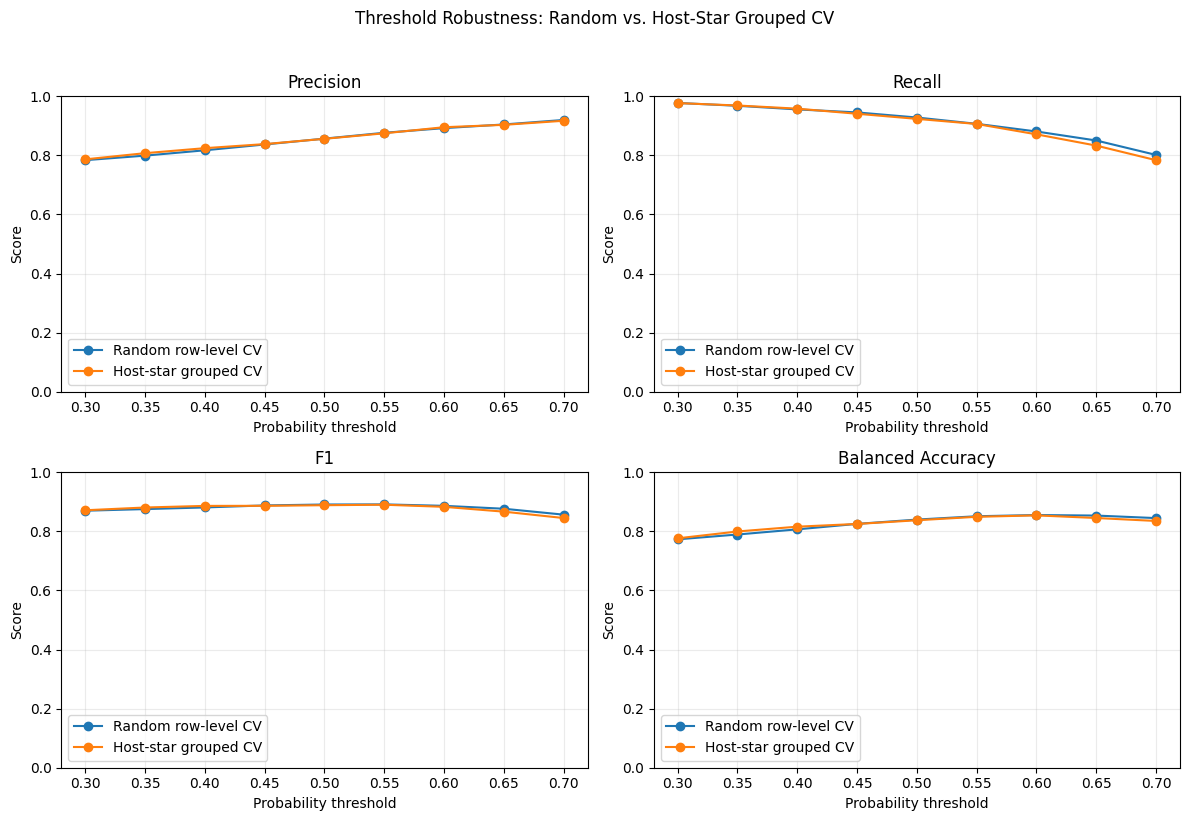

In [7]:
# 5. Plot threshold sensitivity for each metric

metrics_to_plot = ["precision", "recall", "F1", "balanced_accuracy"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, metric in zip(axes.flat, metrics_to_plot):
    for design in ["Random row-level CV", "Host-star grouped CV"]:
        subset = threshold_results[
            threshold_results["validation"] == design
        ]
        ax.plot(
            subset["threshold"], subset[metric],
            marker="o", label=design
        )
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("Probability threshold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle("Threshold Robustness: Random vs. Host-Star Grouped CV", y=1.02)
plt.tight_layout()
plt.show()

In [8]:
# 6. Threshold-independent metrics

overall_rows = []
for design, probabilities in [
    ("Random row-level CV", random_oof),
    ("Host-star grouped CV", grouped_oof)
]:
    overall_rows.append({
        "validation": design,
        "ROC_AUC": roc_auc_score(y, probabilities),
        "average_precision": average_precision_score(y, probabilities),
        "Brier_score_lower_is_better": brier_score_loss(y, probabilities)
    })

overall_metrics = pd.DataFrame(overall_rows)
print("Threshold-independent OOF metrics:")
display(overall_metrics.round(6))

Threshold-independent OOF metrics:


,validation,ROC_AUC,average_precision,Brier_score_lower_is_better
0,Random row-level CV,0.926566,0.946291,0.103626
1,Host-star grouped CV,0.924070,0.943075,0.104792


In [9]:
# 7. Robustness ranges and grouped-minus-random differences

range_rows = []
for design in ["Random row-level CV", "Host-star grouped CV"]:
    subset = threshold_results[threshold_results["validation"] == design]
    for metric in metrics_to_plot:
        range_rows.append({
            "validation": design,
            "metric": metric,
            "minimum_across_thresholds": subset[metric].min(),
            "maximum_across_thresholds": subset[metric].max(),
            "range_width": subset[metric].max() - subset[metric].min()
        })

robustness_ranges = pd.DataFrame(range_rows)
display(robustness_ranges.round(4))

wide = threshold_results.pivot(
    index="threshold", columns="validation", values=metrics_to_plot
)
difference_rows = []
for threshold in THRESHOLDS:
    row = {"threshold": threshold}
    for metric in metrics_to_plot:
        row[metric + "_grouped_minus_random"] = (
            wide.loc[threshold, (metric, "Host-star grouped CV")]
            - wide.loc[threshold, (metric, "Random row-level CV")]
        )
    difference_rows.append(row)

design_differences = pd.DataFrame(difference_rows)
print("Grouped minus random metric differences at each threshold:")
display(design_differences.round(4))

,validation,metric,minimum_across_thresholds,maximum_across_thresholds,range_width
0,Random row-level CV,precision,0.7838,0.9200,0.1362
1,Random row-level CV,recall,0.8016,0.9776,0.1760
2,Random row-level CV,F1,0.8568,0.8915,0.0347
3,Random row-level CV,balanced_accuracy,0.7732,0.8555,0.0823
4,Host-star grouped CV,precision,0.7867,0.9173,0.1306
5,Host-star grouped CV,recall,0.7838,0.9771,0.1933
6,Host-star grouped CV,F1,0.8453,0.8903,0.0450
7,Host-star grouped CV,balanced_accuracy,0.7766,0.8543,0.0777


Grouped minus random metric differences at each threshold:


,threshold,precision_grouped_minus_random,recall_grouped_minus_random,F1_grouped_minus_random,balanced_accuracy_grouped_minus_random
0,0.30,0.0028,-0.0005,0.0015,0.0034
1,0.35,0.0083,0.0010,0.0054,0.0103
2,0.40,0.0072,0.0025,0.0053,0.0090
3,0.45,0.0012,-0.0046,-0.0013,-0.0003
4,0.50,-0.0006,-0.0046,-0.0024,-0.0023
5,0.55,-0.0018,-0.0005,-0.0012,-0.0019
6,0.60,0.0031,-0.0097,-0.0034,-0.0012
7,0.65,-0.0013,-0.0173,-0.0099,-0.0082
8,0.70,-0.0028,-0.0178,-0.0114,-0.0097


In [10]:
# 8. Save outputs for documentation and later analysis

out_dir = "/kaggle/working"

threshold_results.to_csv(
    os.path.join(out_dir, "05_threshold_robustness_metrics.csv"),
    index=False
)
overall_metrics.to_csv(
    os.path.join(out_dir, "05_threshold_independent_metrics.csv"),
    index=False
)
robustness_ranges.to_csv(
    os.path.join(out_dir, "05_threshold_robustness_ranges.csv"),
    index=False
)
design_differences.to_csv(
    os.path.join(out_dir, "05_grouped_vs_random_threshold_differences.csv"),
    index=False
)
oof_predictions.to_csv(
    os.path.join(out_dir, "05_oof_predictions.csv"),
    index=False
)

print("Notebook 05 completed.")
print("Saved files:")
for filename in [
    "05_threshold_robustness_metrics.csv",
    "05_threshold_independent_metrics.csv",
    "05_threshold_robustness_ranges.csv",
    "05_grouped_vs_random_threshold_differences.csv",
    "05_oof_predictions.csv"
]:
    print(os.path.join(out_dir, filename))

Notebook 05 completed.
Saved files:
/kaggle/working/05_threshold_robustness_metrics.csv
/kaggle/working/05_threshold_independent_metrics.csv
/kaggle/working/05_threshold_robustness_ranges.csv
/kaggle/working/05_grouped_vs_random_threshold_differences.csv
/kaggle/working/05_oof_predictions.csv
